In [115]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv2D, Dense, Flatten, Dropout
from tensorflow.keras.models import Model
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [116]:
#Access data file
data = pd.read_csv("/content/drive/MyDrive/AirBnB Analysis/listings.csv")

In [117]:
#Clean duplicaes and missing values from data
print(len(data))

4368


In [118]:
data.drop_duplicates()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,3781,https://www.airbnb.com/rooms/3781,20260919134146,2026-09-20,NaN,Harborside-Walk to subway,Fully separate apartment in a two apartment bu...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,4804,...,4.96,4.85,4.89,NaN,NaN,1,1,0,0,0.20
1,5506,https://www.airbnb.com/rooms/5506,20260919134146,2026-09-20,NaN,** Fort Hill Inn Private! Minutes to center!**,**THE BEST Value in BOSTON!!*** PRIVATE GUEST ...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,8229,...,4.89,4.59,4.78,STR-490093,NaN,11,11,0,0,0.68
2,6695,https://www.airbnb.com/rooms/6695,20260919134146,2026-09-20,NaN,"Fort Hill Inn *Sunny* 1 bedroom, condo duplex","Comfortable, Fully Equipped private apartment...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,8229,...,4.94,4.55,4.73,STR-491702,NaN,11,11,0,0,0.69
3,10811,https://www.airbnb.com/rooms/10811,20260919134146,2026-09-20,previous scrape,Bostons Best Rentals -Studio Prestigious Back Bay,Bostons Best Rentals offers a Stunning Back Ba...,NaN,https://a0.muscache.com/pictures/45735/27548f7...,38997,...,4.00,5.00,4.67,NaN,NaN,10,10,0,0,0.07
4,10813,https://www.airbnb.com/rooms/10813,20260919134146,2026-09-20,NaN,The Back Bay Nook -Brownstone in Prestigious ...,Stunning Back Bay furnished studio apartment. ...,NaN,https://a0.muscache.com/pictures/20b5b9c9-e1f4...,38997,...,5.00,5.00,4.86,NaN,NaN,10,10,0,0,0.08
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4363,1775532758430368587,https://www.airbnb.com/rooms/1775532758430368587,20260919134146,2026-09-20,NaN,Bedroom | 3BR 1B w/AC ~ 2 miles from Longwood Med,"Quite building, off street parking, washer and...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,7427795,...,NaN,NaN,NaN,STR-623189,NaN,5,4,1,0,NaN
4364,1776339304563099291,https://www.airbnb.com/rooms/1776339304563099291,20260919134146,2026-09-20,NaN,"11 Entire Home | BU, Longwood, Green Line to Dtwn",Entire 3-bedroom apartment in the heart of Fen...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,584263709,...,NaN,NaN,NaN,STR-566681,NaN,1,1,0,0,NaN
4365,1776668414494534851,https://www.airbnb.com/rooms/1776668414494534851,20260919134146,2026-09-20,NaN,Renovated 3BR/3BA Historic North End Duplex,Welcome to this renovated three-bedroom duplex...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,31340713,...,NaN,NaN,NaN,NaN,NaN,18,18,0,0,NaN
4366,1777025171707509764,https://www.airbnb.com/rooms/1777025171707509764,20260919134146,2026-09-20,NaN,30+ Day Stay at Lux Boston Apt | Free Parking,Welcome to your brand new luxury Boston getawa...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,556289532,...,NaN,NaN,NaN,STR-641296,NaN,2,2,0,0,NaN


In [119]:
print(len(data))

4368


In [120]:
#Take a look at some summary stats
data.describe()

,id,scrape_id,neighborhood_overview,host_id,host_profile_id,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
count,4.368000e+03,4.368000e+03,0.0,4.368000e+03,4.368000e+03,0.0,4368.000000,4368.000000,4368.000000,4368.000000,...,3578.000000,3579.000000,3578.000000,3578.000000,0.0,4368.000000,4368.000000,4368.000000,4368.000000,3579.000000
mean,8.511560e+17,2.026092e+13,NaN,2.567804e+16,1.476801e+18,NaN,8.046932,5.390110,6.675595,5.597985,...,4.864310,4.854063,4.771699,4.628390,NaN,28.230311,22.811584,4.884844,0.009386,1.853901
std,6.644280e+17,1.590026e+00,NaN,2.073720e+17,4.319704e+16,NaN,4.212290,3.630307,4.284194,3.594517,...,0.290495,0.310563,0.313764,0.400244,NaN,48.643938,47.101413,12.350661,0.096439,2.057323
min,3.781000e+03,2.026092e+13,NaN,4.804000e+03,1.462506e+18,NaN,0.000000,0.000000,0.000000,0.000000,...,1.000000,1.000000,1.000000,1.000000,NaN,1.000000,0.000000,0.000000,0.000000,0.010000
25%,4.571273e+07,2.026092e+13,NaN,2.254157e+07,1.462889e+18,NaN,5.000000,2.000000,3.000000,2.000000,...,4.842500,4.840000,4.680000,4.510000,NaN,2.000000,1.000000,0.000000,0.000000,0.300000
50%,9.811498e+17,2.026092e+13,NaN,1.091463e+08,1.465913e+18,NaN,9.000000,5.000000,7.000000,5.000000,...,4.940000,4.940000,4.870000,4.710000,NaN,7.000000,3.000000,0.000000,0.000000,1.230000
75%,1.467394e+18,2.026092e+13,NaN,4.096843e+08,1.469783e+18,NaN,11.000000,9.000000,10.000000,9.000000,...,5.000000,5.000000,4.990000,4.850000,NaN,34.000000,20.000000,3.000000,0.000000,2.830000
max,1.777541e+18,2.026092e+13,NaN,1.763928e+18,1.766797e+18,NaN,17.000000,11.000000,15.000000,11.000000,...,5.000000,5.000000,5.000000,5.000000,NaN,211.000000,211.000000,65.000000,1.000000,28.300000


In [121]:
#Lets evaulate price, but first change it to a numeric value from a string
data['price'] = data['price'].astype(str).str.replace('$', '').str.replace(',', '').astype(float)
data['price'].describe()

,price
count,3486.000000
mean,315.160186
std,279.658190
min,30.440000
25%,150.105000
50%,253.330000
75%,397.000000
max,4815.000000


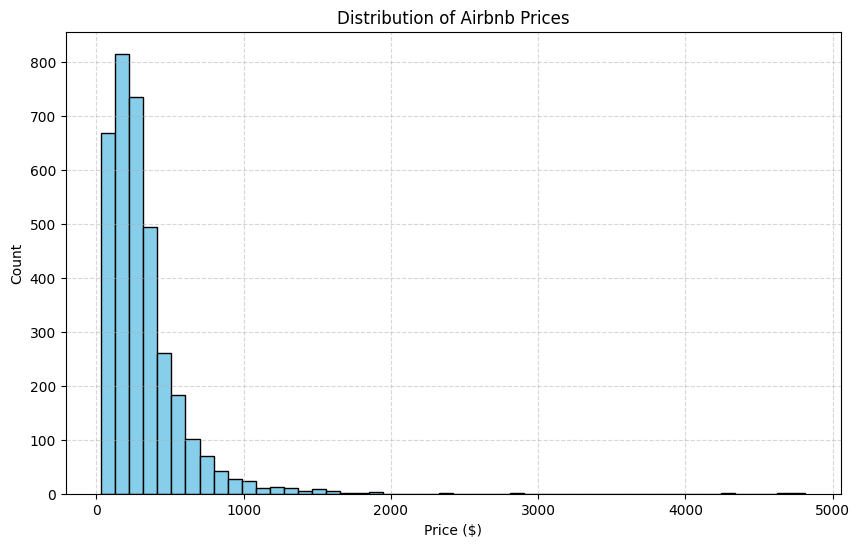

In [122]:
plt.figure(figsize=(10, 6))
plt.hist(data["price"], bins=50, edgecolor='black', color='skyblue')
plt.title('Distribution of Airbnb Prices')
plt.xlabel('Price ($)')
plt.ylabel('Count')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

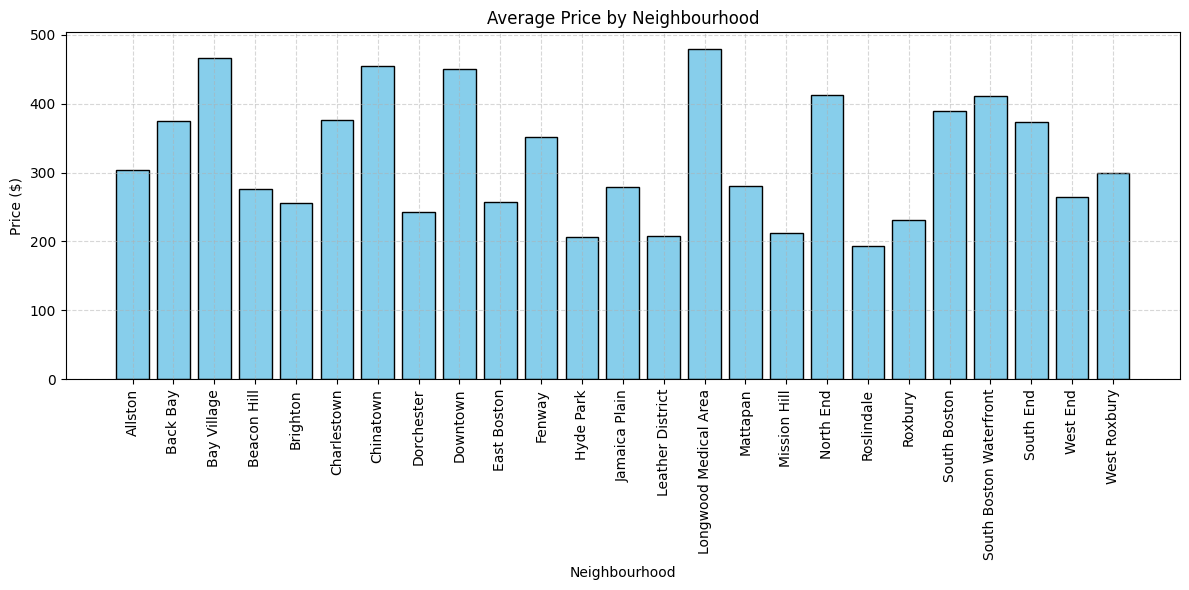

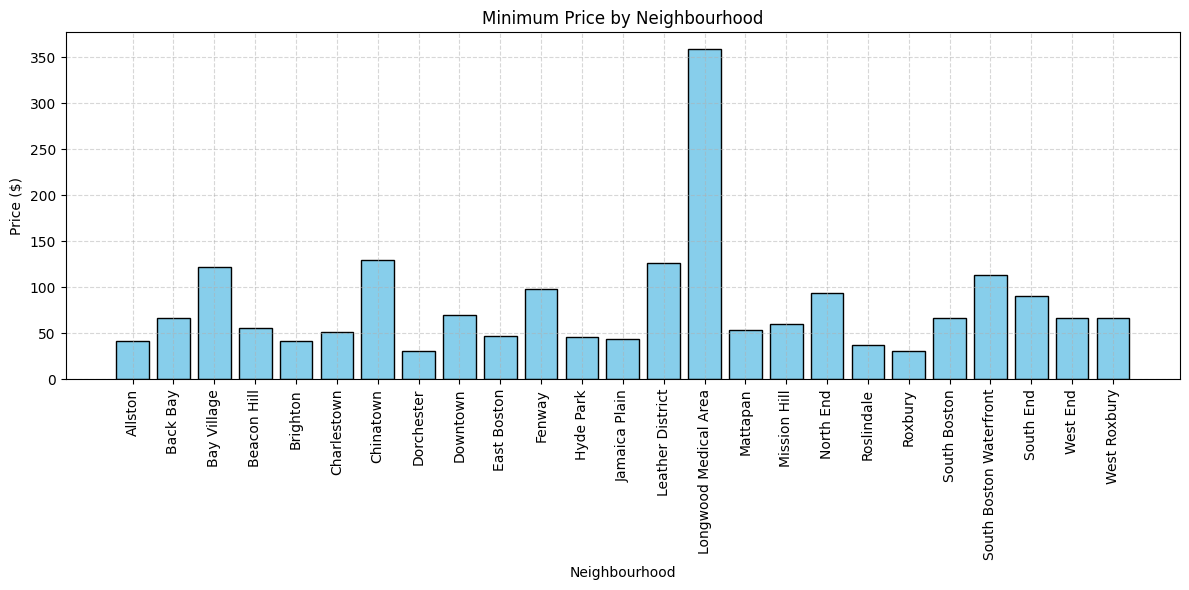

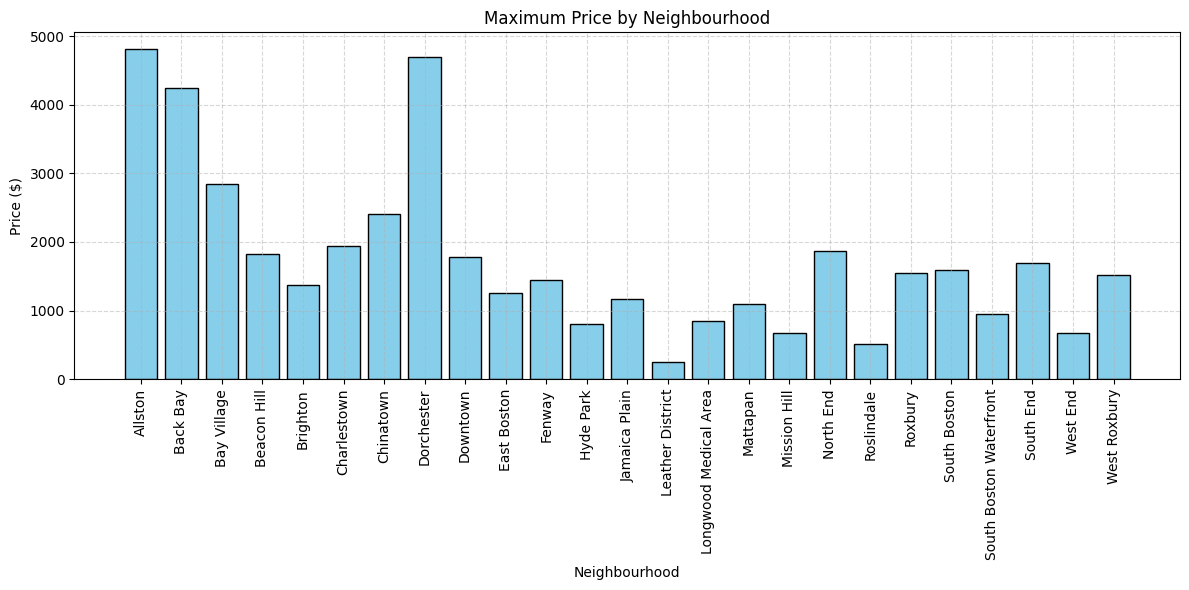

In [123]:
#Lets evaluate the average price for each area of Boston
grouped_mean_price = data.groupby("neighbourhood_cleansed")["price"].mean()

plt.figure(figsize=(12, 6))
plt.bar(grouped_mean_price.index, grouped_mean_price.values, edgecolor='black', color='skyblue')
plt.title('Average Price by Neighbourhood')
plt.xlabel('Neighbourhood')
plt.ylabel('Price ($)')
plt.xticks(rotation=90)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

grouped_min_price = data.groupby("neighbourhood_cleansed")["price"].min()

plt.figure(figsize=(12, 6))
plt.bar(grouped_min_price.index, grouped_min_price.values, edgecolor='black', color='skyblue')
plt.title('Minimum Price by Neighbourhood')
plt.xlabel('Neighbourhood')
plt.ylabel('Price ($)')
plt.xticks(rotation=90)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

grouped_max_price = data.groupby("neighbourhood_cleansed")["price"].max()

plt.figure(figsize=(12, 6))
plt.bar(grouped_max_price.index, grouped_max_price.values, edgecolor='black', color='skyblue')
plt.title('Maximum Price by Neighbourhood')
plt.xlabel('Neighbourhood')
plt.ylabel('Price ($)')
plt.xticks(rotation=90)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [124]:
#Some interesting stuff here, but the count of each location could tell us if any of this is actually meaningful information
data['neighbourhood_cleansed'].value_counts()

,count
neighbourhood_cleansed,
Dorchester,571
Downtown,443
Back Bay,336
Roxbury,295
South End,282
Brighton,263
East Boston,256
Beacon Hill,238
Fenway,234


In [125]:
#Some of these like Dorchester, Downtown, and Back Bay have plenty of values. But other have a lot fewer. Leather district only has 4!

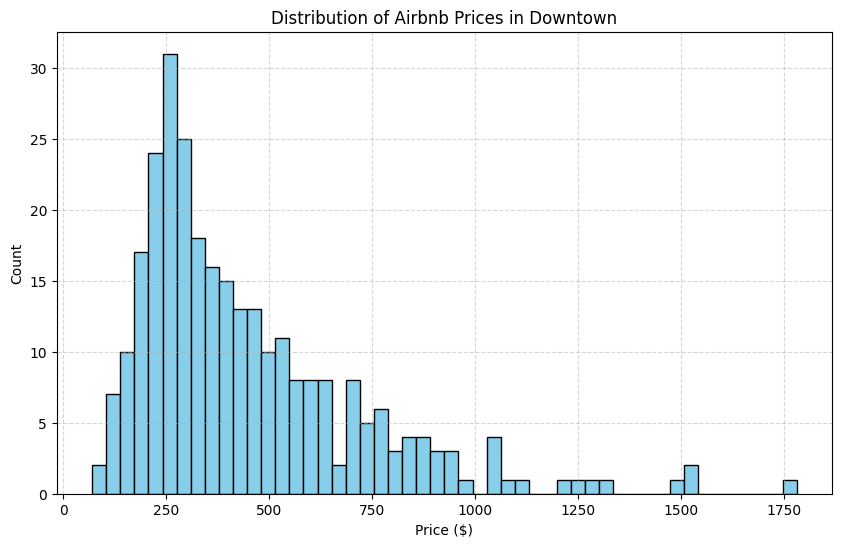

In [126]:
#Lets look at the distribution just one location
downtown_data = (data.where(data["neighbourhood_cleansed"] == "Downtown"))

plt.figure(figsize=(10, 6))
plt.hist(downtown_data["price"], bins=50, edgecolor='black', color='skyblue')
plt.title('Distribution of Airbnb Prices in Downtown')
plt.xlabel('Price ($)')
plt.ylabel('Count')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

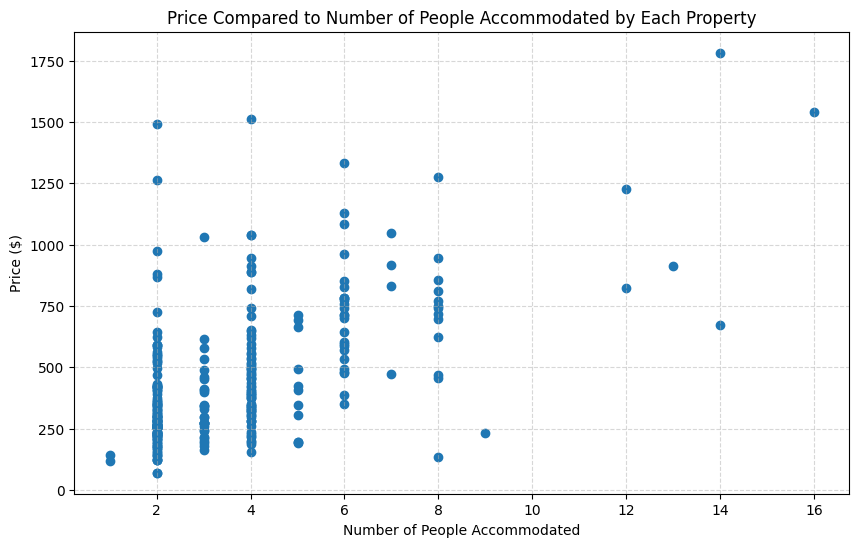

In [127]:
#Lets see these downtown locations in terms of how many people they accomodate
plt.figure(figsize=(10, 6))
plt.scatter(downtown_data["accommodates"], downtown_data["price"])
plt.title('Price Compared to Number of People Accommodated by Each Property')
plt.xlabel('Number of People Accommodated')
plt.ylabel('Price ($)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [128]:
#Very generally, increasing the number of people accommodated increases the price. Could other factors be used to create a price calculator?

In [129]:
# Simplify the data into some variables of interest
model_data = data[['price', 'accommodates', 'bedrooms', 'beds', 'neighbourhood_cleansed', 'property_type']].copy()
model_data = model_data.dropna()

# One-hot encode the categorical variables using pandas get_dummies
model_data = pd.get_dummies(model_data, columns=['neighbourhood_cleansed', 'property_type'], dtype=float)

Y = model_data['price']
X = model_data.drop('price', axis=1)

In [130]:
X_train, X_test, y_train, y_test = train_test_split(X,Y,test_size=0.2)

sc_X = StandardScaler()
X_train = sc_X.fit_transform(X_train)
X_test = sc_X.transform(X_test)

In [142]:
#Lets create a model first
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(55,)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(1)
])

opt = tf.keras.optimizers.Adam(0.1)
model.compile(optimizer=opt, loss='mse', metrics=[tf.keras.metrics.RootMeanSquaredError()])
r = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=100)

Epoch 1/100
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 75361.3438 - root_mean_squared_error: 274.5202 - val_loss: 28562.6660 - val_root_mean_squared_error: 169.0049
Epoch 2/100
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 54944.0312 - root_mean_squared_error: 234.4014 - val_loss: 29121.0312 - val_root_mean_squared_error: 170.6488
Epoch 3/100
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 50827.7070 - root_mean_squared_error: 225.4500 - val_loss: 28490.0762 - val_root_mean_squared_error: 168.7900
Epoch 4/100
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 52841.6680 - root_mean_squared_error: 229.8732 - val_loss: 34671.3164 - val_root_mean_squared_error: 186.2023
Epoch 5/100
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 55326.2148 - root_mean_squared_error: 235.2153 - val_loss: 36576.0703 - val_root_mean_squared_error: 191.2487
Epoch 6/100
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 51668.3047 - root_mean_squared_error: 227.3066 - val_loss: 47337.9688 - val_root_mean_squared_er

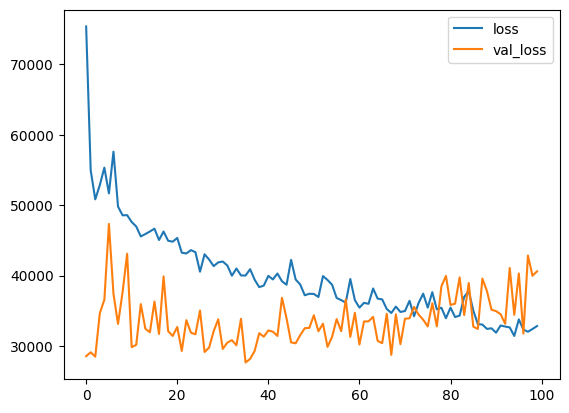

In [143]:
plt.plot(r.history['loss'], label='loss')
plt.plot(r.history['val_loss'], label='val_loss')
plt.legend()
plt.show()

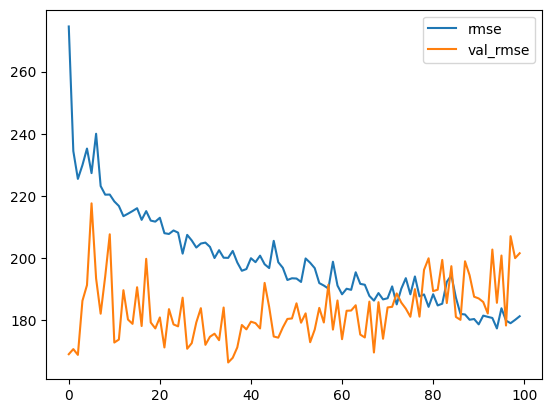

In [145]:
plt.plot(r.history['root_mean_squared_error'], label='rmse')
plt.plot(r.history['val_root_mean_squared_error'], label='val_rmse')
plt.legend()
plt.show()

In [149]:
model_data.head()

,price,accommodates,bedrooms,beds,neighbourhood_cleansed_Allston,neighbourhood_cleansed_Back Bay,neighbourhood_cleansed_Bay Village,neighbourhood_cleansed_Beacon Hill,neighbourhood_cleansed_Brighton,neighbourhood_cleansed_Charlestown,...,property_type_Private room in loft,property_type_Private room in rental unit,property_type_Private room in serviced apartment,property_type_Private room in townhouse,property_type_Private room in villa,property_type_Room in aparthotel,property_type_Room in boutique hotel,property_type_Room in hotel,property_type_Shared room in home,property_type_Shared room in rental unit
0,111.62,2,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,189.00,2,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,254.38,4,0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,134.62,3,0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,169.75,2,0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [156]:
# Create a 55-feature array matching the input structure of X
features = np.zeros((1, 55))

# Set the numeric features: accommodates, bedrooms, beds
features[0, 0] = 4
features[0, 1] = 2
features[0, 2] = 2.0

# Set Back Bay. In the columns list of X, 'neighbourhood_cleansed_Back Bay' is index 4
features[0, 4] = 1.0

#Set the property type to being a private room in an apartment
features[0, 47] = 1.0

# Predict using the standardized features
p_price = model.predict(sc_X.transform(features))
print('Predicted Rental Price:', p_price[0][0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
Predicted Rental Price: 1314.7397


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
